# Caso de estudio 1: datos que merezcan confianza
## Entrega de avance. Brazilian E-Commerce Public Dataset by Olist

**Equipo 6:** Juan Pablo Esteva, Bruno Fidalgo, Ivan Lomando y Francisco Von Sanden

**Cómo reproducir**

1. Instalar las librerías: `pip install -r requirements.txt` (pandas, numpy, matplotlib, seaborn y jupyter).
2. Descargar el ZIP del dataset desde https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce y descomprimir los 9 archivos CSV dentro de `data/raw/`.
3. Ejecutar todas las celdas de este notebook en orden.

**Estructura del proyecto**

| Carpeta | Contenido |
|---|---|
| `data/raw/` | datos originales descargados de Kaggle (no se editan ni se suben al repositorio) |
| `data/interim/` | tablas generadas por el notebook |
| `notebooks/` | este notebook, ejecutable de principio a fin |
| `reports/` | informe, tabla del diagnóstico de calidad y figuras |

**Reglas del proyecto**

- Los archivos de `data/raw/` nunca se modifican; lo que se transforma se guarda en `data/interim/`.
- No se borran filas en silencio: los problemas se marcan con columnas indicadoras y se documentan en la sección 9.3.
- Todo número del informe sale de una celda de este notebook.
- El uso de IA se declara en la sección 10.

## 0. Librerías y rutas

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RUTA_RAW = "../data/raw/"
RUTA_INTERIM = "../data/interim/"
RUTA_FIGS = "../reports/figs/"
os.makedirs(RUTA_INTERIM, exist_ok=True)
os.makedirs(RUTA_FIGS, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Fuente y procedencia

**Cómo obtener los datos:** descargar el ZIP desde https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
y descomprimir los 9 archivos CSV dentro de `data/raw/`. Los datos no se suben al repositorio (están en `.gitignore`).

| Campo | Valor |
|---|---|
| Publicador | Olist, a través de Kaggle (usuario `olistbr`) |
| Licencia | CC BY-NC-SA 4.0 (uso no comercial, con atribución) |
| Fecha de descarga | 21/08/2026 (última actualización del dataset en Kaggle: 01/10/2021) |
| Qué proceso representa | Pedidos hechos entre 2016 y 2018 en marketplaces de Brasil a través de Olist: compra, pago, envío, entrega y reseña posterior del cliente |
| Qué dice la documentación sobre anonimización | Son datos comerciales reales anonimizados. Clientes, vendedores y productos se identifican con hashes, la ubicación se da solo por prefijo de CEP y las menciones a empresas en el texto de las reseñas se reemplazaron por nombres de casas de Game of Thrones |

In [2]:
archivos = sorted(os.listdir(RUTA_RAW))
archivos = [a for a in archivos if a.endswith(".csv")]
print(len(archivos), "archivos CSV encontrados")
for a in archivos:
    tamanio_mb = os.path.getsize(RUTA_RAW + a) / 1_000_000
    print(f"{a:45s} {tamanio_mb:8.2f} MB")

9 archivos CSV encontrados
olist_customers_dataset.csv                       9.03 MB
olist_geolocation_dataset.csv                    61.27 MB
olist_order_items_dataset.csv                    15.44 MB
olist_order_payments_dataset.csv                  5.78 MB
olist_order_reviews_dataset.csv                  14.45 MB
olist_orders_dataset.csv                         17.65 MB
olist_products_dataset.csv                        2.38 MB
olist_sellers_dataset.csv                         0.17 MB
product_category_name_translation.csv             0.00 MB


## 2. Carga e inventario

Los prefijos de código postal (CEP) se leen como texto: son códigos, no números con los que se hagan cuentas.
Si pandas los lee como número, un código que empieza con 0 pierde ese 0.

In [3]:
orders = pd.read_csv(RUTA_RAW + "olist_orders_dataset.csv")
items = pd.read_csv(RUTA_RAW + "olist_order_items_dataset.csv")
payments = pd.read_csv(RUTA_RAW + "olist_order_payments_dataset.csv")
reviews = pd.read_csv(RUTA_RAW + "olist_order_reviews_dataset.csv")
customers = pd.read_csv(RUTA_RAW + "olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
products = pd.read_csv(RUTA_RAW + "olist_products_dataset.csv")
sellers = pd.read_csv(RUTA_RAW + "olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": str})
geolocation = pd.read_csv(RUTA_RAW + "olist_geolocation_dataset.csv", dtype={"geolocation_zip_code_prefix": str})
translation = pd.read_csv(RUTA_RAW + "product_category_name_translation.csv")

tablas = {
    "orders": orders, "items": items, "payments": payments, "reviews": reviews,
    "customers": customers, "products": products, "sellers": sellers,
    "geolocation": geolocation, "translation": translation,
}

### 2.1 Filas, columnas y período de cada tabla

In [4]:
fechas_por_tabla = {
    "orders": ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "items": ["shipping_limit_date"],
    "reviews": ["review_creation_date", "review_answer_timestamp"],
}

inventario = []
for nombre, df in tablas.items():
    fila = {"tabla": nombre, "filas": df.shape[0], "columnas": df.shape[1]}
    if nombre in fechas_por_tabla:
        primera = pd.to_datetime(df[fechas_por_tabla[nombre][0]], errors="coerce")
        fila["desde"] = primera.min().date()
        fila["hasta"] = primera.max().date()
    inventario.append(fila)

inventario = pd.DataFrame(inventario)
inventario

,tabla,filas,columnas,desde,hasta
0,orders,99441,8,2016-09-04,2018-10-17
1,items,112650,7,2016-09-19,2020-04-09
2,payments,103886,5,NaN,NaN
3,reviews,99224,7,2016-10-02,2018-08-31
4,customers,99441,5,NaN,NaN
5,products,32951,9,NaN,NaN
6,sellers,3095,4,NaN,NaN
7,geolocation,1000163,5,NaN,NaN
8,translation,71,2,NaN,NaN


### 2.2 Tipos y primeras filas

In [5]:
for nombre, df in tablas.items():
    print("=" * 20, nombre, "=" * 20)
    print(df.dtypes)
    print()

==================== orders ====================
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

==================== items ====================
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

==================== payments ====================
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object

==================== reviews ====================
review_id                  object
order_id                  

In [6]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [7]:
items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


### 2.3 Grano, claves candidatas y relaciones (hipótesis)

Esto es lo que **suponemos** a partir de los nombres de las columnas y la documentación. Se verifica en la sección 5.

| Tabla | Una fila representa… | Clave candidata | Se relaciona con |
|---|---|---|---|
| orders | un pedido | `order_id` | customers |
| items | un ítem dentro de un pedido | `order_id` + `order_item_id` | orders, products, sellers |
| payments | un pago de un pedido | `order_id` + `payment_sequential` | orders |
| reviews | una reseña | `review_id` | orders |
| customers | un cliente en un pedido (`customer_id` cambia en cada pedido; la persona se identifica con `customer_unique_id`) | `customer_id` | orders |
| products | un producto | `product_id` | translation |
| sellers | un vendedor | `seller_id` | items |
| geolocation | una coordenada (latitud y longitud) observada para un prefijo de CEP | ninguna: el prefijo se repite muchas veces (sección 5.8) | customers, sellers (por prefijo CEP) |
| translation | una categoría | `product_category_name` | products |

**Alcance del avance:** trabajamos con orders, items, payments, reviews, customers, products y translation.
Geolocation y sellers se integran en la entrega final.

## 3. Predicción (antes de explorar)

Antes de seguir con la exploración registramos, el 02/09/2026, los dos problemas de calidad que esperábamos encontrar y por qué. El contraste con la evidencia está en la sección 9.1.

**Problema 1: fechas del ciclo del pedido faltantes o incoherentes con el estado.**
Cada fecha la registra un actor distinto en un momento distinto: la compra la registra la plataforma, la aprobación depende del medio de pago, la entrega al transportista la informa el vendedor y la entrega al cliente la informa la logística. Si un pedido se cancela o queda sin stock nunca llega a las etapas siguientes, así que esperamos ausencias con significado; y como parte del registro es manual, también algunos valores fuera de orden.
Dónde buscarlo: `order_approved_at`, `order_delivered_carrier_date` y `order_delivered_customer_date` cruzadas con `order_status`. Lo confirmaría que los faltantes se concentren en los estados que no llegaron a esa etapa y que aparezcan casos imposibles (un pedido `delivered` sin fecha de entrega, o fechas en orden imposible); lo refutaría que los faltantes estén repartidos parejo entre todos los estados.

**Problema 2: relaciones que no son uno a uno entre el pedido y las reseñas o los pagos.**
Un cliente puede pagar combinando medios (por ejemplo un voucher y una tarjeta) y cada medio queda como un pago separado. La reseña sale de una encuesta posterior a la entrega, que puede quedar asociada a varios pedidos o responderse más de una vez. Si se unen las tablas sin tenerlo en cuenta, los pedidos se repiten y los totales quedan inflados.
Dónde buscarlo: `reviews` (`review_id`, `order_id`) y `payments` (`order_id`, `payment_sequential`). Lo confirmaría que `review_id` no sea único, que haya pedidos con varias reseñas o varios pagos y que al unir sin agrupar se obtengan más filas que pedidos; lo refutaría que ambas tablas tuvieran exactamente una fila por pedido.

## 4. Exploración inicial

Cada gráfico responde una pregunta. Todos llevan título, unidades en los ejes y la población en el título.
Debajo de cada uno escribimos la interpretación.

### 4.1 Conversión de fechas

Se convierten las columnas de fecha. Si algún valor no se puede interpretar, queda como nulo: por eso contamos cuántos nulos nuevos aparecen.

In [8]:
def convertir_fechas(df, columnas):
    for col in columnas:
        nulos_antes = df[col].isna().sum()
        df[col] = pd.to_datetime(df[col], errors="coerce")
        nulos_despues = df[col].isna().sum()
        print(f"{col:35s} valores que no se pudieron convertir: {nulos_despues - nulos_antes}")

convertir_fechas(orders, fechas_por_tabla["orders"])
convertir_fechas(items, fechas_por_tabla["items"])
convertir_fechas(reviews, fechas_por_tabla["reviews"])

order_purchase_timestamp            valores que no se pudieron convertir: 0
order_approved_at                   valores que no se pudieron convertir: 0
order_delivered_carrier_date        valores que no se pudieron convertir: 0
order_delivered_customer_date       valores que no se pudieron convertir: 0
order_estimated_delivery_date       valores que no se pudieron convertir: 0
shipping_limit_date                 valores que no se pudieron convertir: 0
review_creation_date                valores que no se pudieron convertir: 0
review_answer_timestamp             valores que no se pudieron convertir: 0


### 4.2 ¿Qué período cubren los pedidos y es parejo mes a mes?

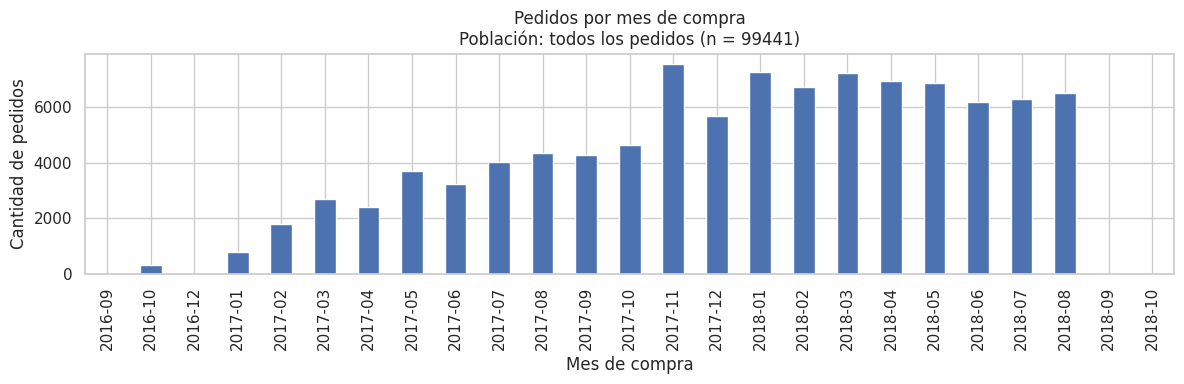

In [9]:
orders["mes_compra"] = orders["order_purchase_timestamp"].dt.to_period("M")
pedidos_por_mes = orders["mes_compra"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
pedidos_por_mes.plot(kind="bar", ax=ax)
ax.set_title(f"Pedidos por mes de compra\nPoblación: todos los pedidos (n = {len(orders)})")
ax.set_xlabel("Mes de compra")
ax.set_ylabel("Cantidad de pedidos")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "01_pedidos_por_mes.png")
plt.show()

In [10]:
pedidos_por_mes

mes_compra
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

**Interpretación:** los pedidos van de setiembre de 2016 a octubre de 2018, pero la cobertura no es pareja. En 2016 hay muy pocos pedidos (4 en setiembre, 324 en octubre, ninguno en noviembre y 1 en diciembre), después crecen durante 2017 con un pico en noviembre de 2017 (7544, posiblemente Black Friday) y se estabilizan entre 6000 y 7300 por mes en 2018. En setiembre y octubre de 2018 hay solo 20 pedidos. **Decisión:** los análisis por mes se limitan a enero de 2017 a agosto de 2018; los meses de los extremos se tratan como cobertura parcial y no como caídas de ventas. **Qué no podemos concluir:** si 2016 es el inicio real de la operación o una carga incompleta, y si el corte de 2018 es la fecha de extracción.

### 4.3 ¿En qué estado están los pedidos?

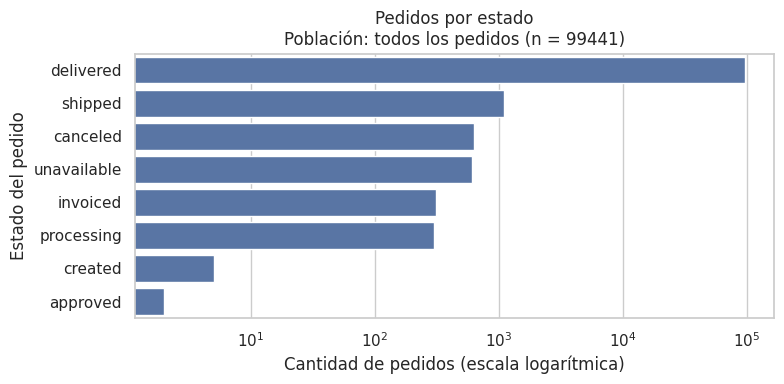

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=orders, y="order_status", order=orders["order_status"].value_counts().index, ax=ax)
ax.set_xscale("log")
ax.set_title(f"Pedidos por estado\nPoblación: todos los pedidos (n = {len(orders)})")
ax.set_xlabel("Cantidad de pedidos (escala logarítmica)")
ax.set_ylabel("Estado del pedido")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "02_pedidos_por_estado.png")
plt.show()

orders["order_status"].value_counts(normalize=True).mul(100).round(2)

**Interpretación:** el 97,02% de los pedidos está `delivered`. El resto se reparte entre estados intermedios (`shipped` 1,11%, `invoiced` 0,32%, `processing` 0,30%) y finales sin entrega (`canceled` 0,63%, `unavailable` 0,61%). **Decisión:** cualquier análisis de tiempos de entrega o de reseñas se hace sobre pedidos `delivered`, y el estado se usa para interpretar los faltantes (4.5).

### 4.4 ¿Qué columnas tienen valores faltantes?

In [12]:
faltantes = []
for nombre, df in tablas.items():
    porcentaje = df.isna().mean() * 100
    for columna, pct in porcentaje.items():
        if pct > 0:
            faltantes.append({"tabla": nombre, "columna": columna, "pct_faltante": round(pct, 2)})

faltantes = pd.DataFrame(faltantes).sort_values("pct_faltante", ascending=False)
faltantes

,tabla,columna,pct_faltante
3,reviews,review_comment_title,88.34
4,reviews,review_comment_message,58.70
2,orders,order_delivered_customer_date,2.98
6,products,product_name_lenght,1.85
5,products,product_category_name,1.85
7,products,product_description_lenght,1.85
8,products,product_photos_qty,1.85
1,orders,order_delivered_carrier_date,1.79
0,orders,order_approved_at,0.16
9,products,product_weight_g,0.01


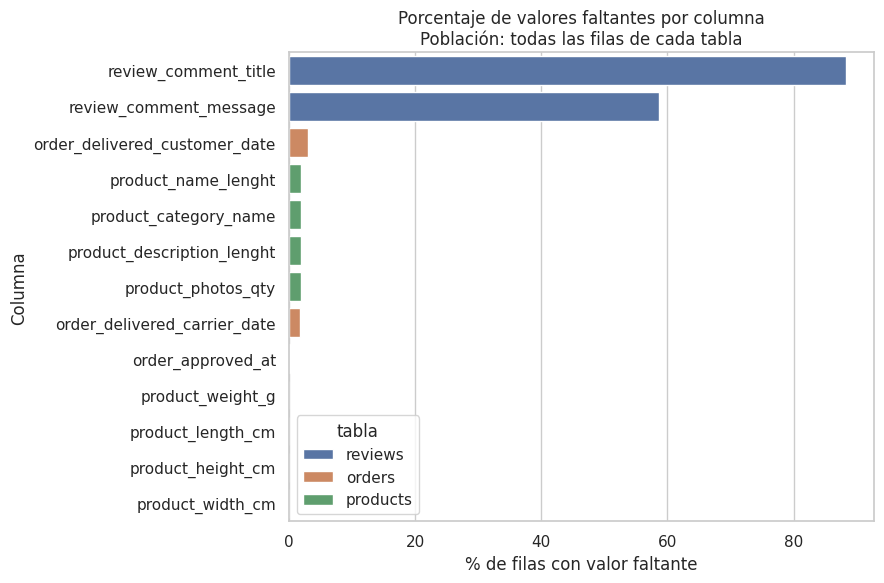

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=faltantes, y="columna", x="pct_faltante", hue="tabla", dodge=False, ax=ax)
ax.set_title("Porcentaje de valores faltantes por columna\nPoblación: todas las filas de cada tabla")
ax.set_xlabel("% de filas con valor faltante")
ax.set_ylabel("Columna")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "03_faltantes_por_columna.png")
plt.show()

**Interpretación:** los faltantes más grandes están en el título (88,34%) y el mensaje (58,70%) de las reseñas, que son campos opcionales. En `orders` faltan fechas de entrega al cliente (2,98%), de entrega al transportista (1,79%) y de aprobación (0,16%). En `products` hay 610 productos (1,85%) sin categoría ni datos descriptivos, y 2 sin dimensiones. **Decisión:** no hay un tratamiento único: primero hay que ver si la falta depende del proceso (4.5 y sección 6).

### 4.5 ¿Los faltantes en las fechas dependen del estado del pedido?
Si la falta depende de una variable que sí observamos, eso ayuda a decidir entre MCAR, MAR y MNAR (sección 6).

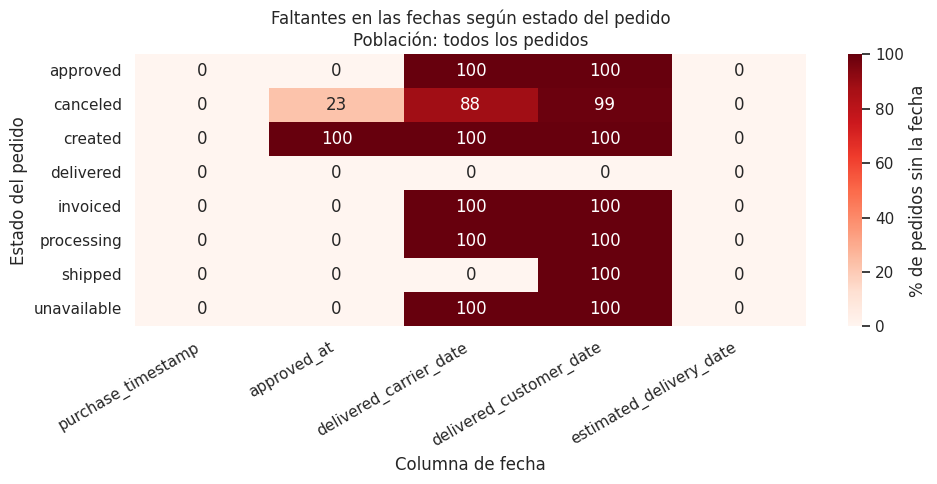

In [14]:
columnas_fecha = fechas_por_tabla["orders"]
faltante_por_estado = orders[columnas_fecha].isna().groupby(orders["order_status"]).mean() * 100

faltante_por_estado.columns = [c.replace("order_", "") for c in faltante_por_estado.columns]

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(faltante_por_estado, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, ax=ax,
            cbar_kws={"label": "% de pedidos sin la fecha"})
ax.set_title("Faltantes en las fechas según estado del pedido\nPoblación: todos los pedidos")
ax.set_xlabel("Columna de fecha")
ax.set_ylabel("Estado del pedido")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(RUTA_FIGS + "04_faltantes_fechas_por_estado.png")
plt.show()

**Interpretación:** las fechas faltan donde el proceso todavía no llegó a esa etapa. `invoiced`, `processing`, `unavailable`, `created` y `approved` no tienen ninguna fecha de entrega; `shipped` tiene fecha de entrega al transportista pero no al cliente; `delivered` tiene las tres fechas casi siempre. En `canceled` falta la aprobación en el 23% de los casos (se cancelaron antes de aprobar el pago) y la entrega al cliente en el 99%. **Decisión:** estas ausencias tienen significado y no se imputan. Los pocos casos que no siguen el patrón (pedidos `delivered` sin fecha, `canceled` con fecha de entrega) se revisan en 5.8. **Qué no podemos concluir:** por qué se cancelaron los pedidos ni si las fechas registradas son exactas.

### 4.6 ¿Cuántos ítems, pagos y reseñas tiene cada pedido?
Si un pedido puede tener varios, unir las tablas sin agruparlas antes repite filas (sección 7).

In [15]:
print("Ítems por pedido:")
print(items.groupby("order_id").size().value_counts().sort_index().head(10))
print("\nPagos por pedido:")
print(payments.groupby("order_id").size().value_counts().sort_index().head(10))
print("\nReseñas por pedido:")
print(reviews.groupby("order_id").size().value_counts().sort_index())

Ítems por pedido:
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
Name: count, dtype: int64

Pagos por pedido:
1     96479
2      2382
3       301
4       108
5        52
6        36
7        28
8        11
9         9
10        5
Name: count, dtype: int64

Reseñas por pedido:
1    98126
2      543
3        4
Name: count, dtype: int64


**Interpretación:** de los 98.666 pedidos con ítems, 88.863 (90,1%) tienen uno solo y el resto tiene dos o más. De los 99.440 pedidos con pagos, 96.479 (97,0%) tienen un pago y el resto combina varios. De los 98.673 pedidos con reseña, 98.126 (99,4%) tienen una y 547 tienen dos o tres. **Decisión:** ninguna de las tres tablas es uno a uno con `orders`, así que se agregan por `order_id` antes de unir (sección 7).

### 4.7 ¿Cómo se distribuyen el precio y el flete? ¿Hay outliers?

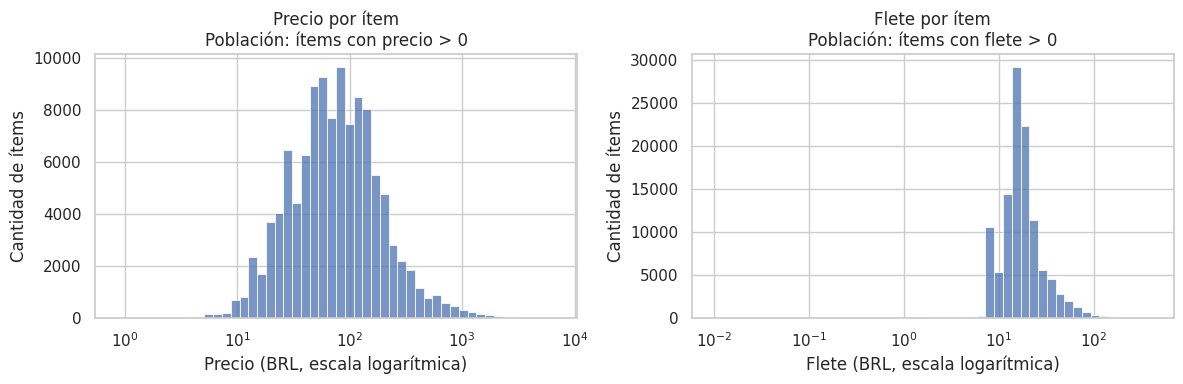

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(items.loc[items["price"] > 0, "price"], log_scale=True, bins=50, ax=axes[0])
axes[0].set_title(f"Precio por ítem\nPoblación: ítems con precio > 0")
axes[0].set_xlabel("Precio (BRL, escala logarítmica)")
axes[0].set_ylabel("Cantidad de ítems")
sns.histplot(items.loc[items["freight_value"] > 0, "freight_value"], log_scale=True, bins=50, ax=axes[1])
axes[1].set_title(f"Flete por ítem\nPoblación: ítems con flete > 0")
axes[1].set_xlabel("Flete (BRL, escala logarítmica)")
axes[1].set_ylabel("Cantidad de ítems")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "05_precio_flete.png")
plt.show()

items[["price", "freight_value"]].describe()

Outliers con la regla del IQR (Q1 − 1,5 × IQR, Q3 + 1,5 × IQR). Un outlier no es necesariamente un error.

In [17]:
for col in ["price", "freight_value"]:
    q1 = items[col].quantile(0.25)
    q3 = items[col].quantile(0.75)
    iqr = q3 - q1
    fuera = (items[col] < q1 - 1.5 * iqr) | (items[col] > q3 + 1.5 * iqr)
    print(f"{col:15s} outliers: {fuera.sum()} ({fuera.mean() * 100:.2f}% de los ítems)")

price           outliers: 8427 (7.48% de los ítems)
freight_value   outliers: 12134 (10.77% de los ítems)


**Interpretación:** precio y flete son muy asimétricos. La mediana del precio es 74,99 BRL y el máximo 6735 BRL. Con la regla del IQR, el 7,48% de los precios y el 10,77% de los fletes quedan fuera de rango. Como superan el 5% (criterio visto en clase), los tomamos como parte de la cola larga de la distribución: productos caros o envíos lejanos o pesados. No hay precios menores o iguales a 0 (sección 5.3). **Decisión:** no se eliminan ni se recortan; se analizan en escala logarítmica y con medianas. **Qué no podemos concluir:** si algún valor extremo puntual es un error de carga; para eso habría que cruzarlo con la categoría y el peso del producto.

### 4.8 ¿Cómo se distribuyen los puntajes de las reseñas?

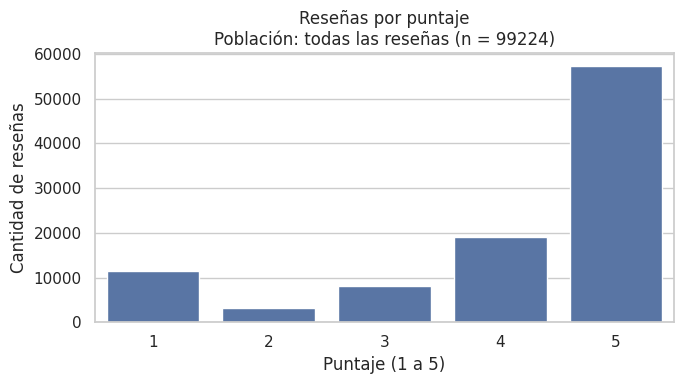

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=reviews, x="review_score", ax=ax)
ax.set_title(f"Reseñas por puntaje\nPoblación: todas las reseñas (n = {len(reviews)})")
ax.set_xlabel("Puntaje (1 a 5)")
ax.set_ylabel("Cantidad de reseñas")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "06_puntaje_resenas.png")
plt.show()

In [19]:
reviews["review_score"].value_counts(normalize=True).sort_index().mul(100).round(1)

review_score
1    11.5
2     3.2
3     8.2
4    19.3
5    57.8
Name: proportion, dtype: float64

**Interpretación:** la distribución está cargada hacia los extremos: 57,8% de las reseñas tiene puntaje 5 y 11,5% tiene puntaje 1, mientras que 2 y 3 juntos suman 11,4%. Todos los puntajes están entre 1 y 5 (sección 5.3). **Decisión:** el promedio esconde esa forma; conviene reportar también el porcentaje de puntajes bajos (1 y 2). **Qué no podemos concluir:** si los clientes que no dejaron reseña habrían puntuado distinto.

## 5. Diagnóstico de calidad

Cada chequeo se guarda en una tabla con: dimensión, regla, filas evaluadas, filas con problema y porcentaje.
El umbral indica cuánto toleramos; si se supera, el estado queda en REVISAR y revisamos esas filas.
Superar el umbral no significa que sea un error. Después cada caso se clasifica como dato inválido, evento poco frecuente,
ausencia con significado, problema de integración o limitación de la fuente.

In [20]:
resultados = []

def registrar(dimension, tabla, regla, evaluadas, con_problema, umbral_pct=0):
    pct = con_problema / evaluadas * 100 if evaluadas > 0 else 0
    estado = "OK" if pct <= umbral_pct else "REVISAR"
    resultados.append({"dimensión": dimension, "tabla": tabla, "regla": regla,
                       "evaluadas": evaluadas, "con_problema": con_problema,
                       "pct": round(pct, 2), "umbral_pct": umbral_pct, "estado": estado})

### 5.1 Unicidad: ¿las claves identifican una sola fila?

In [21]:
registrar("unicidad", "orders", "order_id no se repite",
          len(orders), orders.duplicated(subset=["order_id"]).sum())
registrar("unicidad", "items", "order_id + order_item_id no se repite",
          len(items), items.duplicated(subset=["order_id", "order_item_id"]).sum())
registrar("unicidad", "payments", "order_id + payment_sequential no se repite",
          len(payments), payments.duplicated(subset=["order_id", "payment_sequential"]).sum())
registrar("unicidad", "reviews", "review_id no se repite",
          len(reviews), reviews.duplicated(subset=["review_id"]).sum())
registrar("unicidad", "customers", "customer_id no se repite",
          len(customers), customers.duplicated(subset=["customer_id"]).sum())
registrar("unicidad", "products", "product_id no se repite",
          len(products), products.duplicated(subset=["product_id"]).sum())

for nombre, df in tablas.items():
    registrar("unicidad", nombre, "no hay filas completamente repetidas", len(df), df.duplicated().sum())

### 5.2 Completitud: ¿qué columnas superan el 5% de faltantes?

In [22]:
for _, fila in faltantes.iterrows():
    df = tablas[fila["tabla"]]
    registrar("completitud", fila["tabla"], f"{fila['columna']} no es nulo",
              len(df), df[fila["columna"]].isna().sum(), umbral_pct=5)

### 5.3 Validez: ¿los valores están dentro de lo posible?

In [23]:
registrar("validez", "items", "price > 0", len(items), (items["price"] <= 0).sum())
registrar("validez", "items", "freight_value >= 0", len(items), (items["freight_value"] < 0).sum())
registrar("validez", "reviews", "review_score entre 1 y 5", len(reviews), (~reviews["review_score"].between(1, 5)).sum())
registrar("validez", "payments", "payment_value > 0", len(payments), (payments["payment_value"] <= 0).sum())
registrar("validez", "payments", "payment_installments >= 1", len(payments), (payments["payment_installments"] < 1).sum())

con_peso = products["product_weight_g"].notna()
registrar("validez", "products", "product_weight_g > 0", con_peso.sum(), (products.loc[con_peso, "product_weight_g"] <= 0).sum())

largo_cep = customers["customer_zip_code_prefix"].str.len()
registrar("validez", "customers", "prefijo CEP tiene 5 dígitos", len(customers), (largo_cep != 5).sum())

estados_validos = ["created", "approved", "invoiced", "processing", "shipped", "delivered", "canceled", "unavailable"]
registrar("validez", "orders", "order_status es un estado conocido", len(orders), (~orders["order_status"].isin(estados_validos)).sum())

La lista de estados válidos incluye todos los estados que aparecen en `orders` (sección 4.3).

### 5.4 Consistencia entre columnas y tablas

In [24]:
# Orden de las fechas (solo donde existen las dos)
ambas = orders["order_purchase_timestamp"].notna() & orders["order_approved_at"].notna()
registrar("consistencia", "orders", "compra <= aprobación", ambas.sum(),
          (orders.loc[ambas, "order_purchase_timestamp"] > orders.loc[ambas, "order_approved_at"]).sum())

ambas = orders["order_delivered_carrier_date"].notna() & orders["order_delivered_customer_date"].notna()
registrar("consistencia", "orders", "entrega a transportista <= entrega al cliente", ambas.sum(),
          (orders.loc[ambas, "order_delivered_carrier_date"] > orders.loc[ambas, "order_delivered_customer_date"]).sum())

# Estado vs fecha de entrega
entregados = orders[orders["order_status"] == "delivered"]
registrar("consistencia", "orders", "si está delivered, tiene fecha de entrega", len(entregados),
          entregados["order_delivered_customer_date"].isna().sum())

# Lo pagado vs precio + flete de los ítems (tolerancia de 1 BRL por redondeos)
total_items = items.groupby("order_id")[["price", "freight_value"]].sum()
total_items["total_items"] = total_items["price"] + total_items["freight_value"]
total_pagado = payments.groupby("order_id")["payment_value"].sum()
comparacion = total_items[["total_items"]].join(total_pagado, how="inner")
comparacion["diferencia"] = comparacion["payment_value"] - comparacion["total_items"]
registrar("consistencia", "orders", "lo pagado coincide con precio + flete (±1 BRL)", len(comparacion),
          (comparacion["diferencia"].abs() > 1).sum(), umbral_pct=1)

### 5.5 Integridad entre tablas: ¿las claves existen en la tabla de origen?

In [25]:
registrar("integridad", "items", "order_id existe en orders", len(items), (~items["order_id"].isin(orders["order_id"])).sum())
registrar("integridad", "payments", "order_id existe en orders", len(payments), (~payments["order_id"].isin(orders["order_id"])).sum())
registrar("integridad", "reviews", "order_id existe en orders", len(reviews), (~reviews["order_id"].isin(orders["order_id"])).sum())
registrar("integridad", "orders", "customer_id existe en customers", len(orders), (~orders["customer_id"].isin(customers["customer_id"])).sum())
registrar("integridad", "items", "product_id existe en products", len(items), (~items["product_id"].isin(products["product_id"])).sum())

con_categoria = products["product_category_name"].notna()
registrar("integridad", "products", "la categoría tiene traducción", con_categoria.sum(),
          (~products.loc[con_categoria, "product_category_name"].isin(translation["product_category_name"])).sum())

### 5.6 Cobertura: ¿todos los pedidos tienen ítems, pagos y reseña?

Esto no es necesariamente un error: hay que cruzarlo con el estado del pedido antes de decidir.

In [26]:
registrar("cobertura", "orders", "el pedido tiene ítems", len(orders), (~orders["order_id"].isin(items["order_id"])).sum())
registrar("cobertura", "orders", "el pedido tiene pagos", len(orders), (~orders["order_id"].isin(payments["order_id"])).sum())
registrar("cobertura", "orders", "el pedido tiene reseña", len(orders), (~orders["order_id"].isin(reviews["order_id"])).sum())

### 5.7 Tabla resumen del diagnóstico

In [27]:
perfil_calidad = pd.DataFrame(resultados)
perfil_calidad.to_csv("../reports/perfil_calidad_avance.csv", index=False)
print(perfil_calidad["estado"].value_counts())
perfil_calidad.sort_values(["estado", "pct"], ascending=[False, False])

estado
OK         36
REVISAR    13
Name: count, dtype: int64


,dimensión,tabla,regla,evaluadas,con_problema,pct,umbral_pct,estado
15,completitud,reviews,review_comment_title no es nulo,99224,87656,88.34,5,REVISAR
16,completitud,reviews,review_comment_message no es nulo,99224,58247,58.70,5,REVISAR
13,unicidad,geolocation,no hay filas completamente repetidas,1000163,261831,26.18,0,REVISAR
3,unicidad,reviews,review_id no se repite,99224,814,0.82,0,REVISAR
46,cobertura,orders,el pedido tiene ítems,99441,775,0.78,0,REVISAR
48,cobertura,orders,el pedido tiene reseña,99441,768,0.77,0,REVISAR
45,integridad,products,la categoría tiene traducción,32341,13,0.04,0,REVISAR
37,consistencia,orders,entrega a transportista <= entrega al cliente,96475,23,0.02,0,REVISAR
31,validez,payments,payment_value > 0,103886,9,0.01,0,REVISAR
33,validez,products,product_weight_g > 0,32949,4,0.01,0,REVISAR


### 5.8 Revisar las filas con problema
Para cada regla en REVISAR miramos las filas afectadas. Empezamos por el orden de las fechas y seguimos con el resto.

In [28]:
ambas = orders["order_delivered_carrier_date"].notna() & orders["order_delivered_customer_date"].notna()
problema = ambas & (orders["order_delivered_carrier_date"] > orders["order_delivered_customer_date"])
orders.loc[problema, ["order_id", "order_status", "order_delivered_carrier_date", "order_delivered_customer_date"]].head()

,order_id,order_status,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-28 16:57:58,2017-07-25 19:32:56
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-07 17:22:41,2017-07-06 14:27:51
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-20 19:22:02,2017-07-19 14:13:28
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-08-01 18:23:30,2017-07-26 18:09:10
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-20 23:03:42,2017-07-20 18:52:41


In [29]:
print(orders.loc[problema, "order_status"].value_counts())
orders.loc[problema, "order_delivered_carrier_date"].dt.to_period("M").value_counts()

order_status
delivered    23
Name: count, dtype: int64


order_delivered_carrier_date
2017-07    7
2017-08    6
2016-10    4
2017-06    2
2017-03    2
2017-02    2
Freq: M, Name: count, dtype: int64

In [30]:
(orders.loc[problema, "order_delivered_carrier_date"] - orders.loc[problema, "order_delivered_customer_date"]).describe()

count                           23
mean     3 days 06:27:18.478260869
std      3 days 17:18:29.050924326
min                0 days 00:23:18
25%                0 days 23:20:18
50%                1 days 15:51:52
75%         5 days 08:45:32.500000
max               16 days 02:18:29
dtype: object

In [31]:
orders[(orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()][
    ["order_id", "order_approved_at", "order_delivered_carrier_date", "order_estimated_delivery_date"]]

,order_id,order_approved_at,order_delivered_carrier_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:56:40,2017-11-30 18:12:23,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 07:19:05,2018-06-25 08:05:00,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,2018-07-01 17:15:12,2018-07-03 13:57:00,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,2018-07-01 22:15:14,2018-07-03 13:57:00,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,2018-07-01 21:29:54,2018-07-03 09:28:00,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:30:16,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,2018-06-08 12:36:39,2018-06-12 14:10:00,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,2018-06-27 16:29:30,2018-07-03 19:26:00,2018-07-19


In [32]:
print(orders.loc[orders["order_approved_at"].isna(), "order_status"].value_counts())
print(((orders["order_status"] != "delivered") & orders["order_delivered_customer_date"].notna()).sum(),
      "pedidos que no están delivered pero tienen fecha de entrega al cliente")

order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64
6 pedidos que no están delivered pero tienen fecha de entrega al cliente


In [33]:
items[items["shipping_limit_date"] > orders["order_purchase_timestamp"].max()].merge(
    orders[["order_id", "order_status", "order_purchase_timestamp"]], on="order_id")

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_status,order_purchase_timestamp
0,13bdf405f961a6deec817d817f5c6624,1,96ea060e41bdecc64e2de00b97068975,7a241947449cc45dbfda4f9d0798d9d0,2020-02-05 03:30:51,69.99,14.66,canceled,2017-03-16 02:30:51
1,9c94a4ea2f7876660fa6f1b59b69c8e6,1,282b126b2354516c5f400154398f616d,7a241947449cc45dbfda4f9d0798d9d0,2020-02-03 20:23:22,75.99,14.70,shipped,2017-03-14 19:23:22
2,c2bb89b5c1dd978d507284be78a04cb2,1,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44,delivered,2017-05-23 22:28:36
3,c2bb89b5c1dd978d507284be78a04cb2,2,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44,delivered,2017-05-23 22:28:36


In [34]:
sin_items = ~orders["order_id"].isin(items["order_id"])
sin_resena = ~orders["order_id"].isin(reviews["order_id"])
sin_pago = ~orders["order_id"].isin(payments["order_id"])
pd.DataFrame({
    "sin ítems": orders.loc[sin_items, "order_status"].value_counts(),
    "sin reseña": orders.loc[sin_resena, "order_status"].value_counts(),
    "sin pago": orders.loc[sin_pago, "order_status"].value_counts(),
}).fillna(0).astype(int)

,sin ítems,sin reseña,sin pago
order_status,,,
canceled,164,20,0
created,5,2,0
delivered,0,646,1
invoiced,2,5,0
processing,0,6,0
shipped,1,75,0
unavailable,603,14,0


In [35]:
repetidas = reviews[reviews["review_id"].duplicated(keep=False)]
print(repetidas["review_id"].nunique(), "review_id aparecen en más de un pedido")
print((repetidas.groupby("review_id")["review_score"].nunique() > 1).sum(), "de ellos tienen puntajes distintos")

varias = reviews[reviews["order_id"].duplicated(keep=False)]
print((varias.groupby("order_id")["review_score"].nunique() > 1).sum(), "de", varias["order_id"].nunique(),
      "pedidos con varias reseñas tienen puntajes distintos")

789 review_id aparecen en más de un pedido
0 de ellos tienen puntajes distintos


202 de 547 pedidos con varias reseñas tienen puntajes distintos


In [36]:
payments[(payments["payment_value"] <= 0) | (payments["payment_installments"] < 1)]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.00
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.00
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.00
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.00


In [37]:
cuotas = payments.groupby("order_id")["payment_installments"].max().rename("cuotas")
con_diferencia = comparacion[comparacion["diferencia"].abs() > 1].join(cuotas)
print((con_diferencia["diferencia"] > 0).sum(), "pedidos pagaron más que precio + flete y",
      (con_diferencia["diferencia"] < 0).sum(), "pagaron menos")
print(f"Pagaron en más de una cuota: {(con_diferencia['cuotas'] > 1).mean() * 100:.1f}% de los pedidos con diferencia, "
      f"{(comparacion.join(cuotas)['cuotas'] > 1).mean() * 100:.1f}% de todos los pedidos comparados")
con_diferencia["diferencia"].describe()

232 pedidos pagaron más que precio + flete y 17 pagaron menos
Pagaron en más de una cuota: 94.8% de los pedidos con diferencia, 51.5% de todos los pedidos comparados


count    249.000000
mean      11.514819
std       19.351849
min      -51.620000
25%        3.290000
50%        6.980000
75%       14.120000
max      182.810000
Name: diferencia, dtype: float64

In [38]:
sin_traduccion = products["product_category_name"].notna() & ~products["product_category_name"].isin(translation["product_category_name"])
print(products.loc[sin_traduccion, "product_category_name"].value_counts())

descriptivas = ["product_category_name", "product_name_lenght", "product_description_lenght", "product_photos_qty"]
sin_descripcion = products[descriptivas].isna().all(axis=1)
print(sin_descripcion.sum(), "productos no tienen ninguna de las cuatro columnas descriptivas")
print(items["product_id"].isin(products.loc[sin_descripcion, "product_id"]).sum(), "ítems vendidos corresponden a esos productos")

products[products["product_weight_g"] <= 0]

product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: count, dtype: int64
610 productos no tienen ninguna de las cuatro columnas descriptivas
1603 ítems vendidos corresponden a esos productos


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0


In [39]:
print(geolocation["geolocation_zip_code_prefix"].nunique(), "prefijos de CEP distintos en", len(geolocation), "filas")
geolocation.groupby("geolocation_zip_code_prefix").size().describe()

19015 prefijos de CEP distintos en 1000163 filas


count    19015.000000
mean        52.598633
std         72.057907
min          1.000000
25%         10.000000
50%         29.000000
75%         66.500000
max       1146.000000
dtype: float64

In [40]:
reviews["review_comment_message"].isna().groupby(reviews["review_score"]).mean().mul(100).round(1)

review_score
1    23.5
2    31.9
3    56.5
4    68.8
5    64.1
Name: review_comment_message, dtype: float64

## 6. Mecanismo de los faltantes (MCAR / MAR / MNAR)

Para cada columna con faltantes relevantes indicamos el mecanismo más probable, la evidencia y la acción, siguiendo lo visto en clase:
MCAR con imputación simple, MAR con imputación condicionada y MNAR con un indicador, sin imputar.
MAR y MNAR no se pueden distinguir solo con los datos, así que nos apoyamos en cómo funciona el proceso.

| Tabla.columna | % faltante | Mecanismo probable | Evidencia (sección) | Acción |
|---|---|---|---|---|
| orders.order_delivered_customer_date | 2,98 | MAR respecto de `order_status` (la falta la explica el estado; en la práctica es una ausencia con significado) | 4.5: 100% de faltantes en estados que no llegaron a la entrega; 8 casos `delivered` sin fecha (5.8) | No imputar. Analizar solo pedidos `delivered` con fecha; marcar los 8 `delivered` sin fecha |
| orders.order_delivered_carrier_date | 1,79 | MAR respecto de `order_status` | 4.5: falta en todos los estados anteriores al despacho y en el 88% de `canceled` | No imputar; se usa como dato de etapa, no como variable a completar |
| orders.order_approved_at | 0,16 | MAR respecto de `order_status` en `canceled` y `created`; sin explicación en 14 `delivered` | 5.8: 141 `canceled`, 5 `created`, 14 `delivered` | No imputar; marcar los 14 `delivered` sin aprobación |
| products.product_category_name (y nombre, descripción y fotos) | 1,85 | No es MCAR: faltan las cuatro columnas juntas en los mismos 610 productos. Mecanismo desconocido (posible falla de carga del catálogo) | 5.8: 610 productos sin ninguna columna descriptiva, 1603 ítems vendidos | No imputar la categoría; asignar una etiqueta explícita `sin_categoria` en la versión curada |
| products.product_weight_g y dimensiones | 0,01 | MCAR plausible (2 productos) | 4.4 | Dejar nulo; no afecta las preguntas del avance |
| reviews.review_comment_message | 58,70 | MAR respecto de `review_score`, aunque también podría ser MNAR (quien no tiene nada que decir no escribe) | 5.8: falta en 23,5% de las reseñas con puntaje 1 y en 64,1% de las de puntaje 5 | No imputar; el comentario es opcional. Usar un indicador `tiene_comentario` si se analiza |
| reviews.review_comment_title | 88,34 | Ausencia con significado (campo opcional) | 4.4 | No imputar; no se usa en el avance |

## 7. Integración preliminar

**Decisión preliminar de grano: una fila por pedido.**
Como un pedido puede tener varios ítems, pagos o reseñas, primero se agrupan por `order_id` y después se unen.
En cada unión se controla que la cantidad de filas no cambie.

In [41]:
# Ítems agrupados por pedido
items_por_pedido = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    total_precio=("price", "sum"),
    total_flete=("freight_value", "sum"),
).reset_index()

# Pagos agrupados por pedido
pagos_por_pedido = payments.groupby("order_id").agg(
    n_pagos=("payment_sequential", "count"),
    total_pagado=("payment_value", "sum"),
).reset_index()

# Reseñas: si un pedido tiene más de una, nos quedamos con la más reciente y guardamos cuántas tenía
n_resenas = reviews.groupby("order_id").size().rename("n_resenas").reset_index()
resena_reciente = (reviews.sort_values("review_creation_date")
                   .drop_duplicates(subset="order_id", keep="last")[["order_id", "review_score"]])
resenas_por_pedido = n_resenas.merge(resena_reciente, on="order_id")

In [42]:
pedidos = orders.merge(customers[["customer_id", "customer_unique_id", "customer_state"]],
                       on="customer_id", how="left", validate="many_to_one")
print("orders + customers:", len(orders), "->", len(pedidos))

pedidos = pedidos.merge(items_por_pedido, on="order_id", how="left", validate="one_to_one")
print("+ ítems:           ", len(orders), "->", len(pedidos))

pedidos = pedidos.merge(pagos_por_pedido, on="order_id", how="left", validate="one_to_one")
print("+ pagos:           ", len(orders), "->", len(pedidos))

pedidos = pedidos.merge(resenas_por_pedido, on="order_id", how="left", validate="one_to_one")
print("+ reseñas:         ", len(orders), "->", len(pedidos))

assert len(pedidos) == len(orders), "Alguna unión cambió la cantidad de filas"

orders + customers: 99441 -> 99441


+ ítems:            99441 -> 99441


+ pagos:            99441 -> 99441


+ reseñas:          99441 -> 99441


`validate` hace que pandas dé error si la relación no es la esperada (por ejemplo, si una clave que debería ser única está repetida).

### 7.1 Marcar problemas en lugar de borrar filas

In [43]:
pedidos["sin_items"] = pedidos["n_items"].isna()
pedidos["sin_pago"] = pedidos["n_pagos"].isna()
pedidos["sin_resena"] = pedidos["n_resenas"].isna()
pedidos["varias_resenas"] = pedidos["n_resenas"] > 1
pedidos["dias_vs_estimado"] = (pedidos["order_delivered_customer_date"] - pedidos["order_estimated_delivery_date"]).dt.days

marcas = ["sin_items", "sin_pago", "sin_resena", "varias_resenas"]
print(pedidos[marcas].sum())

pedidos.to_csv(RUTA_INTERIM + "pedidos_preliminar.csv", index=False)
print("\nGuardado:", len(pedidos), "pedidos en data/interim/pedidos_preliminar.csv")

sin_items         775
sin_pago            1
sin_resena        768
varias_resenas    547
dtype: int64



Guardado: 99441 pedidos en data/interim/pedidos_preliminar.csv


### 7.2 ¿Por qué importa el grano?
Si unimos la reseña a cada ítem, un pedido con 5 ítems cuenta 5 veces. Comparamos el promedio de puntaje con los dos granos.

In [44]:
promedio_por_pedido = pedidos["review_score"].mean()
items_con_resena = items[["order_id"]].merge(resena_reciente, on="order_id", how="left")
promedio_por_item = items_con_resena["review_score"].mean()

print(f"Puntaje promedio, una fila por pedido: {promedio_por_pedido:.3f}")
print(f"Puntaje promedio, una fila por ítem:   {promedio_por_item:.3f}")

Puntaje promedio, una fila por pedido: 4.086
Puntaje promedio, una fila por ítem:   4.033


**Interpretación y decisión de grano:** con una fila por pedido el puntaje promedio es 4,086; con una fila por ítem baja a 4,033. La diferencia aparece porque, al pasar a ítems, un pedido con varios ítems cuenta varias veces, y esos pedidos tienen en promedio peor puntaje. La reseña es del pedido, no del ítem. **Decisión:** el producto curado preliminar tiene grano **pedido** (99.441 filas, mismo número que `orders`, verificado con `validate` y el `assert`). Es el grano que necesitan P1 y P2. P3 necesita grano ítem y queda para la entrega final.

## 8. Preguntas del equipo

- **P1:** ¿En qué estados de Brasil conviene priorizar una revisión del servicio logístico? Población: pedidos `delivered` con fecha de entrega y fecha estimada. Dato: porcentaje de pedidos entregados después de `order_estimated_delivery_date`, por `customer_state`.
- **P2:** ¿Se puede usar el puntaje de la reseña como indicador de satisfacción con la entrega? Población: pedidos `delivered` con fecha de entrega y con reseña. Dato: distribución y promedio de `review_score` en pedidos entregados a tiempo y tarde.
- **P3:** ¿El valor pagado sirve para medir la facturación por categoría de producto? Población: pedidos con ítems y pagos, y productos con categoría. Dato: `payment_value` comparado con `price` + `freight_value`, y `product_category_name` traducida.

En el avance respondemos P1 y P2. P3 necesita grano ítem y queda para la entrega final.

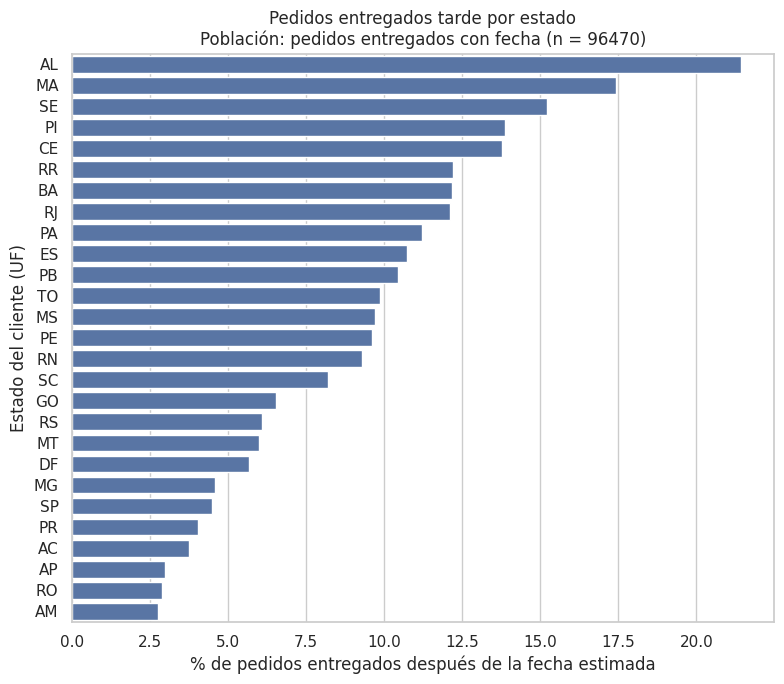

,customer_state,pedidos,pct_tarde
1,AL,397,21.410579
9,MA,717,17.433752
24,SE,335,15.223881
16,PI,476,13.865546
5,CE,1279,13.760751
21,RR,41,12.195122
4,BA,3256,12.162162
18,RJ,12350,12.105263
13,PA,946,11.205074
7,ES,1995,10.726817


In [45]:
# P1: ¿qué porcentaje de pedidos llega después de la fecha estimada, por estado de Brasil?
entregados = pedidos[(pedidos["order_status"] == "delivered") & pedidos["dias_vs_estimado"].notna()].copy()
entregados["llego_tarde"] = entregados["dias_vs_estimado"] > 0
entregados["entrega"] = entregados["llego_tarde"].map({True: "tarde", False: "a tiempo"})

por_estado = entregados.groupby("customer_state").agg(
    pedidos=("order_id", "count"),
    pct_tarde=("llego_tarde", "mean"),
).reset_index()
por_estado["pct_tarde"] = por_estado["pct_tarde"] * 100
por_estado = por_estado.sort_values("pct_tarde", ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(data=por_estado, y="customer_state", x="pct_tarde", ax=ax)
ax.set_title(f"Pedidos entregados tarde por estado\nPoblación: pedidos entregados con fecha (n = {len(entregados)})")
ax.set_xlabel("% de pedidos entregados después de la fecha estimada")
ax.set_ylabel("Estado del cliente (UF)")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "07_entregas_tarde_por_estado.png")
plt.show()

por_estado

**Interpretación:** el porcentaje de pedidos entregados después de la fecha estimada va de 2,8% (AM) a 21,4% (AL). Los estados con más retrasos son del norte y nordeste (AL 21,4%, MA 17,4%, SE 15,2%), y los del sur y sudeste están entre los más bajos (SP 4,5% con 40.494 pedidos, PR 4,0%, MG 4,6%). RJ es una excepción dentro del sudeste: 12,1% con 12.350 pedidos. **Decisión preliminar:** AL, MA, CE, BA y RJ son candidatos a revisión porque combinan porcentaje alto con suficientes pedidos. **Qué no podemos concluir:** en estados con pocos pedidos (RR 41, AP 67, AC 80) el porcentaje es inestable y no permite ordenarlos. Tampoco sabemos si el retraso se debe a la logística o a que la fecha estimada se calcula distinto según la región.

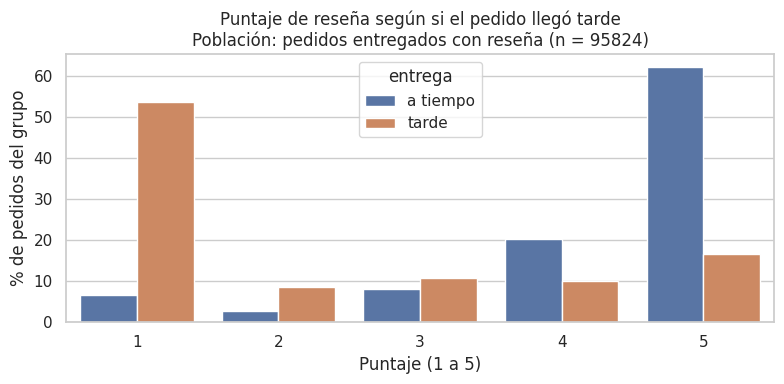

,count,mean
entrega,,
a tiempo,89443,4.290274
tarde,6381,2.270804


In [46]:
# P2: ¿los pedidos que llegan tarde tienen peores reseñas?
con_resena = entregados[entregados["review_score"].notna()]

distribucion = (con_resena.groupby("entrega")["review_score"]
                .value_counts(normalize=True).mul(100).rename("pct").reset_index())
distribucion["review_score"] = distribucion["review_score"].astype(int)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=distribucion, x="review_score", y="pct", hue="entrega", ax=ax)
ax.set_title(f"Puntaje de reseña según si el pedido llegó tarde\nPoblación: pedidos entregados con reseña (n = {len(con_resena)})")
ax.set_xlabel("Puntaje (1 a 5)")
ax.set_ylabel("% de pedidos del grupo")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "08_puntaje_vs_demora.png")
plt.show()

con_resena.groupby("entrega")["review_score"].agg(["count", "mean"])

**Interpretación:** los pedidos entregados a tiempo tienen un puntaje promedio de 4,29 (89.443 pedidos) y los entregados tarde de 2,27 (6.381 pedidos). La diferencia es grande y se ve en toda la distribución (figura 08). Esto apoya usar la reseña como señal de satisfacción con la entrega. **Qué todavía no podemos concluir:** que la demora cause el puntaje bajo (puede haber otros factores, como el producto o el vendedor). Además, la población excluye los 646 pedidos entregados sin reseña, y en 202 pedidos con varias reseñas nos quedamos con la más reciente, que puede no ser la representativa.

## 9. Contraste, hallazgos y decisiones

### 9.1 Predicción vs. evidencia
| Predicción (sección 3) | ¿Se confirmó? | Evidencia | Qué no esperábamos |
|---|---|---|---|
| Problema 1: fechas faltantes o incoherentes con el estado | Sí | Los faltantes se concentran en estados que no llegaron a esa etapa (4.5). Hay casos incoherentes: 8 `delivered` sin fecha de entrega, 14 `delivered` sin aprobación, 23 con entrega al transportista posterior a la entrega al cliente y 6 no entregados con fecha de entrega (5.8) | Que el 23% de los cancelados no tuviera aprobación; y fechas límite de envío en 2020 para 3 pedidos de 2017 del mismo vendedor |
| Problema 2: relaciones que no son uno a uno | Sí, en parte | 547 pedidos con 2 o 3 reseñas (202 con puntajes distintos), 789 `review_id` compartidos por varios pedidos y 3,0% de pedidos con varios pagos (4.6, 5.8). Agregando antes de unir, el producto conserva 99.441 filas (7) | Que los `review_id` compartidos tengan siempre el mismo puntaje (una encuesta para varios pedidos). Lo pagado coincide con precio + flete en el 99,75% de los pedidos, y las diferencias que hay se explican por pagos en cuotas. Tampoco esperábamos 775 pedidos sin ítems |

### 9.2 Hallazgos principales
Cada hallazgo incluye la evidencia, una posible explicación, la decisión que provoca y lo que todavía no podemos concluir.

**H1. Las fechas faltantes son en su mayoría ausencias con significado.** Evidencia: 4.5 y 5.8. Explicación: cada fecha se registra al llegar a una etapa. Decisión: no imputar; analizar entregas solo sobre `delivered` con fecha y marcar los casos incoherentes. No podemos concluir: si las fechas registradas son exactas.

**H2. La reseña no tiene relación uno a uno con el pedido.** Evidencia: 547 pedidos con varias reseñas y 789 `review_id` repetidos entre pedidos (5.8). Explicación: una encuesta puede cubrir varios pedidos y un cliente puede responder más de una vez. Decisión: la clave de `reviews` es `review_id` + `order_id`; se conserva la reseña más reciente por pedido y se marca `varias_resenas`. No podemos concluir: cuál de las reseñas refleja mejor la experiencia.

**H3. Hay pedidos sin ítems, sin reseña o sin pago, y no siempre es un error.** Evidencia: 775 sin ítems (603 `unavailable`, 164 `canceled`), 768 sin reseña (646 `delivered`) y 1 `delivered` sin pago (5.8). Explicación: los pedidos sin stock o cancelados no llegan a tener ítems; las reseñas son voluntarias. Decisión: marcar con `sin_items`, `sin_resena` y `sin_pago` en lugar de borrar. No podemos concluir: por qué 3 pedidos `invoiced` o `shipped` y 5 `created` no tienen ítems.

**H4. El valor pagado no siempre es precio + flete.** Evidencia: 249 pedidos (0,25%) difieren en más de 1 BRL, 232 pagaron de más y el 94,8% de ellos pagó en cuotas, contra el 51,5% del total (5.8). Explicación probable: los intereses de las cuotas. Decisión: para medir facturación por categoría (P3) usar `price` y no `payment_value`. No podemos concluir: el monto exacto de intereses, que el dataset no documenta.

### 9.3 Decisiones preliminares de integración y curación

Estado: preliminar (entrega de avance). Entre paréntesis se indica la sección de este notebook de donde sale la evidencia.

| ID | Tema | Decisión | Alternativas consideradas | Justificación (evidencia) | Filas afectadas | Estado |
|---|---|---|---|---|---|---|
| D01 | Fuente | Los CSV originales se guardan en `data/raw/`, no se editan y no se suben al repo; lo transformado va a `data/interim/` | Trabajar directamente sobre los CSV | La consigna exige no sobrescribir la fuente (sección 1) | Ninguna | Firme |
| D02 | Tipos | Los prefijos de CEP se leen como texto | Dejar el tipo que infiere pandas | Son códigos, no cantidades; como número pierden los ceros iniciales (sección 2, regla de 5 dígitos en 5.3) | Ninguna fila cambia; afecta la columna de prefijo en 99.441 clientes, 3.095 vendedores y 1.000.163 filas de geolocation. 0 prefijos de clientes con largo distinto de 5 | Firme |
| D03 | Fechas | Fechas convertidas con `pd.to_datetime(errors="coerce")`, contando los valores que no se pudieron convertir | Convertir sin contar | Evita que un valor inválido se convierta en nulo sin que lo notemos (4.1) | 0 valores no convertidos en las 8 columnas de fecha | Firme |
| D04 | Grano | Producto curado preliminar: una fila por pedido | Una fila por ítem | La reseña es del pedido: con grano pedido el puntaje promedio es 4,086 y con grano ítem 4,033 (7.2). P1 y P2 son preguntas sobre pedidos; P3 necesita grano ítem y se resuelve en la final | Producto de 99.441 filas, igual que `orders` | Preliminar |
| D05 | Uniones | Tablas hijas agregadas antes de unir; si hay varias reseñas por pedido se conserva la más reciente y se marca | Promedio de puntajes; descartar pedidos con varias reseñas | `review_id` no es único: 814 filas repetidas y 789 ids compartidos por varios pedidos, siempre con el mismo puntaje (5.1, 5.8). 547 pedidos tienen 2 o 3 reseñas y 202 con puntajes distintos (4.6, 5.8): promediar mezcla respuestas distintas y descartar perdería 547 pedidos. Las uniones se validan con `validate` y `assert` (7) | 551 reseñas no pasan al producto; 547 pedidos marcados con `varias_resenas` | Preliminar |
| D06 | Alcance | Avance centrado en orders, items, payments, reviews, customers, products y translation; geolocation y sellers se integran en la final | Integrar las 9 tablas desde el avance | Tiempo disponible; ambas tablas igual se cargan e inventarían (sección 2) | - | Preliminar |
| D07 | Marcas | Los pedidos sin ítems, sin pago o sin reseña se marcan con columnas indicadoras y no se borran | Borrar esos pedidos | Muchos son ausencias con significado: de los 775 sin ítems, 603 son `unavailable` y 164 `canceled`; de los 768 sin reseña, 646 están `delivered` (5.8) | 775 `sin_items`, 1 `sin_pago`, 768 `sin_resena`, 547 `varias_resenas` | Preliminar |
| D08 | Población P1 y P2 | Los análisis de entrega usan solo pedidos `delivered` con fecha de entrega al cliente | Usar todos los pedidos con fecha de entrega | 8 `delivered` no tienen fecha y 6 pedidos no entregados sí la tienen (5.8); las fechas faltantes son ausencias con significado (4.5, sección 6) | 96.470 pedidos en P1; 95.824 en P2 (89.443 a tiempo y 6.381 tarde) | Preliminar |
| D09 | Período | Los análisis por mes se limitan a enero de 2017 a agosto de 2018 | Usar todo el período | 2016 tiene un mes sin pedidos y meses con 1 y 4 pedidos; setiembre y octubre de 2018 suman 20 pedidos (4.2) | 329 pedidos de 2016 y 20 de 2018 quedan fuera de los análisis mensuales | Propuesta, no implementada |
| D10 | Categorías | Traducir a mano las 2 categorías sin traducción y asignar `sin_categoria` a los productos sin categoría | Dejar nulos; descartar los productos | 13 productos tienen categoría sin traducción (`portateis_cozinha_e_preparadores_de_alimentos`, `pc_gamer`) y 610 no tienen categoría ni datos descriptivos, con 1.603 ítems vendidos (5.5, 5.8) | 623 productos | Propuesta para la final |
| D11 | Montos | Para medir facturación por categoría (P3) se usa `price` y no `payment_value` | Usar `payment_value` | 249 pedidos pagan distinto de precio + flete; el 94,8% de ellos pagó en cuotas, contra 51,5% del total (5.8) | Ninguna fila; define la métrica | Propuesta para la final |

**Clasificación de las reglas en REVISAR**

| Regla | Clasificación | Qué vimos al revisar las filas (5.8) | Tratamiento propuesto |
|---|---|---|---|
| reviews: `review_id` no se repite (814, 0,82%) | Problema de integración | 789 `review_id` aparecen en más de un pedido y ninguno con puntajes distintos: una misma encuesta quedó asociada a varios pedidos | La clave de `reviews` pasa a ser `review_id` + `order_id`; no se deduplica por `review_id` (D05) |
| geolocation: filas repetidas (261.831, 26,18%) | Limitación de la fuente | Varias coordenadas por prefijo: 19.015 prefijos en 1.000.163 filas, mediana de 29 filas por prefijo | Fuera del alcance del avance; en la final se agrega a una coordenada por prefijo |
| reviews: `review_comment_title` y `review_comment_message` no nulos (88,34% y 58,70%) | Ausencia con significado | Campos opcionales; el mensaje falta más en puntajes altos (64,1% en 5) que en bajos (23,5% en 1) | No imputar; el umbral de 5% no aplica a campos opcionales. Indicador `tiene_comentario` si se usa |
| orders: el pedido tiene ítems (775, 0,78%) | Ausencia con significado (767) y dato a revisar (8) | 603 `unavailable` y 164 `canceled`; quedan 5 `created`, 2 `invoiced` y 1 `shipped` | Marcar `sin_items` (D07); los 8 casos se reportan como posibles errores |
| orders: el pedido tiene reseña (768, 0,77%) | Limitación de la fuente | 646 están `delivered`: la reseña es voluntaria o no se respondió antes del corte | Marcar `sin_resena`; quedan fuera de la población de P2 |
| orders: el pedido tiene pagos (1) | Problema de integración | Un pedido `delivered` sin ningún pago registrado | Marcar `sin_pago`; excluir de P3 |
| products: la categoría tiene traducción (13, 0,04%) | Problema de integración | Dos categorías no están en la tabla de traducción | Traducción manual documentada (D10) |
| orders: entrega al transportista <= entrega al cliente (23, 0,02%) | Dato inválido | Todos `delivered`; diferencia mediana de 1 día y 16 horas y máxima de 16 días; 15 de los 23 son de junio a agosto de 2017 y 4 de octubre de 2016 | Marcar; excluir de cálculos de tiempo de tránsito. No afectan P1 |
| payments: `payment_value` > 0 (9, 0,01%) | Evento poco frecuente (6) y dato inválido (3) | 6 son vouchers de valor 0 dentro de pedidos con otros pagos; 3 son `not_defined` con valor 0 | Mantener los vouchers; marcar los `not_defined` |
| products: `product_weight_g` > 0 (4, 0,01%) | Dato inválido | 4 productos de `cama_mesa_banho` con peso 0 y dimensiones idénticas (30 × 25 × 30 cm) | Pasar el peso a nulo en la versión curada y marcar |
| orders: si está `delivered`, tiene fecha de entrega (8, 0,01%) | Dato inválido | 7 tienen fecha de entrega al transportista y 1 no tiene ninguna | Marcar; excluir de P1 y P2 (D08) |
| payments: `payment_installments` >= 1 (2, 0,00%) | Dato inválido | 2 pagos con tarjeta de crédito con 0 cuotas y valor positivo | Tratar como 1 cuota en la versión curada y marcar |
| Sin regla todavía: `shipping_limit_date` posterior al último pedido (4 ítems) | Dato inválido | 3 pedidos de marzo y mayo de 2017, del mismo vendedor, con fecha límite de envío en 2020 | Agregar la regla en la final; marcar los ítems |
| Sin regla todavía: pedido no `delivered` con fecha de entrega (6) | Dato inválido o estado desactualizado | Pedidos con fecha de entrega al cliente que no están `delivered` (5.8) | Agregar la regla en la final; marcar |

### 9.4 Pendiente para la entrega final
Versión curada con contrato, controles que fallen ante datos incompatibles, comparación antes/después,
integración de geolocation y sellers, y pruebas con casos que violen al menos tres reglas.

## 10. Uso de IA

Seguimos la secuencia del curso: predecir, intentar, consultar, verificar y declarar. No compartimos con la IA datos sensibles, credenciales ni información personal.

| Fecha | Integrante | Herramienta | Para qué | Qué produjo | Qué modificamos | Cómo lo validamos |
|---|---|---|---|---|---|---|
| 22-08 | Bruno | Claude Opus 5 | Planificar la entrega de avance y armar el esqueleto del repositorio | Estructura del repo y esqueleto del notebook (carga, inventario, chequeos de calidad, integración preliminar) y plantillas de documentación. Se pidió una segunda versión limitada a lo visto en UT1 y UT2 | Modificamos algún bloque del notebook, el cual era innecesario o redundante para la primer entrega | Ejecutamos el notebook, y fuimos viendo bloque a bloque que nos daba para así completarlo a nuestro gusto |
| 11-09 | Juan Pablo Esteva | Claude Opus 5 | Ayudarnos con la escritura y composición de los documentos | Documentos corregidos sintácticamente y más prolijos de lo que los teníamos, entre ellos, predicción, preguntas P1 a P3, interpretaciones del notebook, tabla de mecanismos de faltantes, registro de decisiones D02 a D11 e informe de avance | Vocabulario, tablas y estilos finales | Repaso en lectura de todos los documentos entregados y comparación punto a punto con la info que ya teníamos |